# TLS processor walkthrough

This notebook demonstrates analysis-ready processing of the Ankasa TLS mesh and tree model. File parsing remains the responsibility of `TLSProvider`; `TLSProcessor` validates those datasets and performs spatial preparation and structural summaries.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from tomo_canopy.processors import TLSProcessor

## Locate the TLS sources

Set `CRS` from authoritative source metadata before integrating these coordinates with another sensor.

In [2]:
project_root = next(
    path
    for path in (Path.cwd(), Path.cwd().parent)
    if (path / "pyproject.toml").exists()
)
data_dir = project_root / "data" / "TLS" / "Ankasa"
mesh_path = data_dir / "c01_r02_subsampled_1cm_trees_mesh.ply"
trees_path = data_dir / "c01_r02_subsampled_1cm_trees.txt"
CRS = None  # Example: "EPSG:32630"; verify this from source metadata.

assert mesh_path.exists(), f"Missing {mesh_path}"
assert trees_path.exists(), f"Missing {trees_path}"

## Open and validate the mesh

`TLSProcessor.open` delegates reading to its provider and validates the resulting geometry. Binary vertex and face arrays remain memory-mapped.

In [3]:
processor = TLSProcessor()
mesh = processor.open(mesh_path, crs=CRS)
processor.validate(mesh, check_finite=True)
mesh

<xarray.Dataset> Size: 357MB
Dimensions:        (vertex: 6930014, face: 13600632, corner: 3)
Coordinates:
    x              (vertex) float64 55MB 5.339e+05 5.339e+05 ... 5.34e+05
    y              (vertex) float64 55MB 5.823e+05 5.823e+05 ... 5.823e+05
    z              (vertex) float64 55MB 123.5 123.5 123.5 ... 118.1 118.1 118.2
Dimensions without coordinates: vertex, face, corner
Data variables:
    red            (vertex) uint8 7MB 192 192 192 192 192 ... 192 192 192 192
    green          (vertex) uint8 7MB 166 166 166 166 166 ... 166 166 166 166
    blue           (vertex) uint8 7MB 141 141 141 141 141 ... 141 141 141 141
    alpha          (vertex) uint8 7MB 255 255 255 255 255 ... 255 255 255 255
    face_vertices  (face, corner) int32 163MB 2 1 0 ... 6930012 6930007 6930013
Attributes:
    source:         /home/simon/Documents/science/GFZ/projects/biomass-hackat...
    source_format:  PLY
    ply_format:     binary_little_endian
    geometry_type:  triangular_mesh

## Spatial bounds and local coordinates

Local coordinates improve numerical stability and make plots easier to read. The processor records the global origin in dataset attributes.

In [4]:
bounds = processor.bounds(mesh)
bounds

<xarray.Dataset> Size: 60B
Dimensions:  (axis: 3)
Coordinates:
  * axis     (axis) <U1 12B 'x' 'y' 'z'
Data variables:
    minimum  (axis) float64 24B 5.339e+05 5.823e+05 115.2
    maximum  (axis) float64 24B 5.34e+05 5.824e+05 158.9
Attributes:
    geometry_type:  triangular_mesh

In [5]:
local_mesh = processor.to_local_coordinates(mesh)
print(
    "Local origin:",
    local_mesh.attrs["coordinate_origin_x"],
    local_mesh.attrs["coordinate_origin_y"],
    local_mesh.attrs["coordinate_origin_z"],
)

Local origin: 533919.3076324627 582307.4019274487 115.18136853859242


## Reproducible point-cloud preview

A sampled set of mesh vertices is suitable for a quick Matplotlib preview. Sampling removes face connectivity because the selected vertices no longer form the original surface.

In [6]:
preview = processor.sample_vertices(local_mesh, count=100_000, seed=42)
preview

<xarray.Dataset> Size: 4MB
Dimensions:           (point: 100000)
Coordinates:
    x                 (point) float64 800kB 0.06594 0.1557 ... 65.12 64.99
    y                 (point) float64 800kB 1.389 1.351 1.089 ... 30.72 30.75
    z                 (point) float64 800kB 8.338 9.602 12.16 ... 2.775 3.023
    source_vertex_id  (point) int64 800kB 5 20 90 ... 6929669 6929826 6929854
Dimensions without coordinates: point
Data variables:
    red               (point) uint8 100kB 192 192 192 192 ... 192 192 192 192
    green             (point) uint8 100kB 166 166 166 166 ... 166 166 166 166
    blue              (point) uint8 100kB 141 141 141 141 ... 141 141 141 141
    alpha             (point) uint8 100kB 255 255 255 255 ... 255 255 255 255
Attributes:
    source:                 /home/simon/Documents/science/GFZ/projects/biomas...
    source_format:          PLY
    ply_format:             binary_little_endian
    geometry_type:          point_cloud
    coordinates_are_local:  True
    coordinate_origin_x:    533919.3076324627
    coordinate_origin_y:    582307.4019274487
    coordinate_origin_z:    115.18136853859242
    sampled_from_geometry:  triangular_mesh
    sample_seed:            42
    source_element_count:   6930014

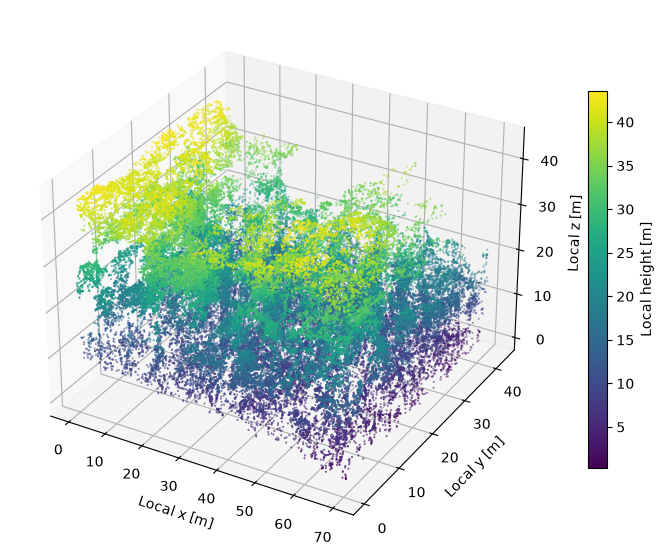

In [7]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection="3d")
points = ax.scatter(
    preview.x,
    preview.y,
    preview.z,
    c=preview.z,
    cmap="viridis",
    s=0.2,
)
ax.set(xlabel="Local x [m]", ylabel="Local y [m]", zlabel="Local z [m]")
fig.colorbar(points, ax=ax, label="Local height [m]", shrink=0.7)
plt.show()

## Process tree structure

The tree model retains radii and parent relationships. `tree_metrics` summarizes each reconstructed tree.

In [8]:
trees = processor.open(trees_path, crs=CRS)
metrics = processor.tree_metrics(trees)
metrics

<xarray.Dataset> Size: 169kB
Dimensions:         (tree: 2225)
Coordinates:
    tree_id         (tree) int32 9kB 0 1 2 3 4 5 ... 2220 2221 2222 2223 2224
Dimensions without coordinates: tree
Data variables:
    segment_count   (tree) int64 18kB 47 39 99 33 178 21 ... 34 27 20 24 57 42
    height          (tree) float64 18kB 5.203 3.571 3.54 ... 0.7667 2.41 2.052
    maximum_radius  (tree) float64 18kB 0.054 0.0449 0.0475 ... 0.0342 0.0317
    x_minimum       (tree) float64 18kB 5.339e+05 5.339e+05 ... 5.34e+05
    x_maximum       (tree) float64 18kB 5.339e+05 5.339e+05 ... 5.34e+05
    y_minimum       (tree) float64 18kB 5.823e+05 5.823e+05 ... 5.823e+05
    y_maximum       (tree) float64 18kB 5.823e+05 5.823e+05 ... 5.823e+05
    z_minimum       (tree) float64 18kB 123.5 123.5 123.4 ... 117.9 117.1 116.2
    z_maximum       (tree) float64 18kB 128.7 127.1 127.0 ... 118.7 119.5 118.3
Attributes:
    source_geometry_type:  tree_segments
    source:                /home/simon/Documents/science/GFZ/projects/biomass...

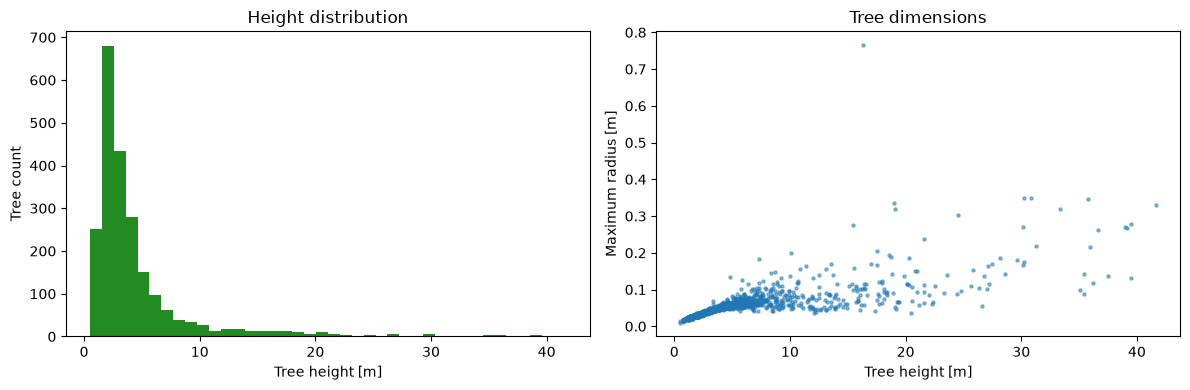

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(metrics.height, bins=40, color="forestgreen")
axes[0].set(xlabel="Tree height [m]", ylabel="Tree count")
axes[0].set_title("Height distribution")

axes[1].scatter(metrics.height, metrics.maximum_radius, s=5, alpha=0.5)
axes[1].set(xlabel="Tree height [m]", ylabel="Maximum radius [m]")
axes[1].set_title("Tree dimensions")
plt.tight_layout()
plt.show()

## Plot an individual tree

Each non-root segment is connected to its local `parent_id`. Line width is scaled by segment radius.

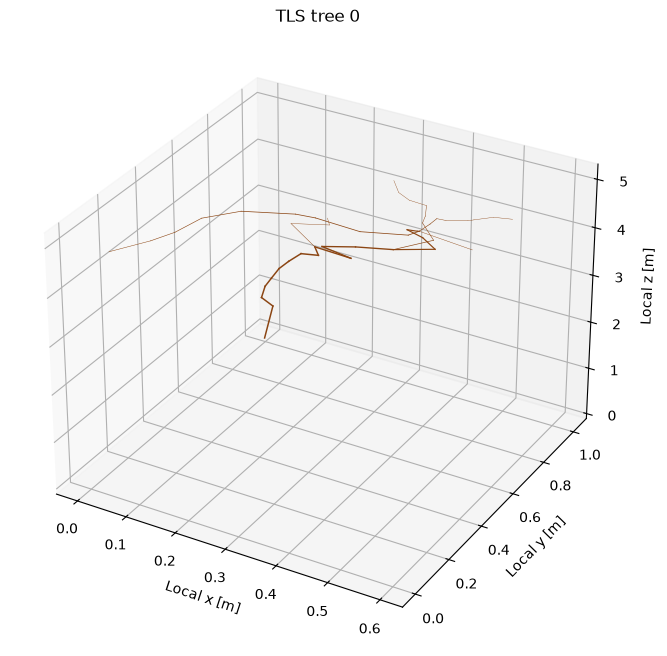

In [10]:
selected_tree_id = 0
tree_indices = np.flatnonzero(trees.tree_id.data == selected_tree_id)
tree = processor.to_local_coordinates(trees.isel(segment=tree_indices))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
for segment_index in range(tree.sizes["segment"]):
    parent_index = int(tree.parent_id.data[segment_index])
    if parent_index < 0:
        continue
    ax.plot(
        [tree.x.data[parent_index], tree.x.data[segment_index]],
        [tree.y.data[parent_index], tree.y.data[segment_index]],
        [tree.z.data[parent_index], tree.z.data[segment_index]],
        color="saddlebrown",
        linewidth=max(0.25, float(tree.radius.data[segment_index]) * 20),
    )
ax.set(xlabel="Local x [m]", ylabel="Local y [m]", zlabel="Local z [m]")
ax.set_title(f"TLS tree {selected_tree_id}")
plt.show()